=== Accuracy Comparison ===
Decision Tree (GINI) Accuracy: 94.15%
Random Forest (Bagging) Accuracy: 97.08%
AdaBoost (Boosting) Accuracy: 97.08%


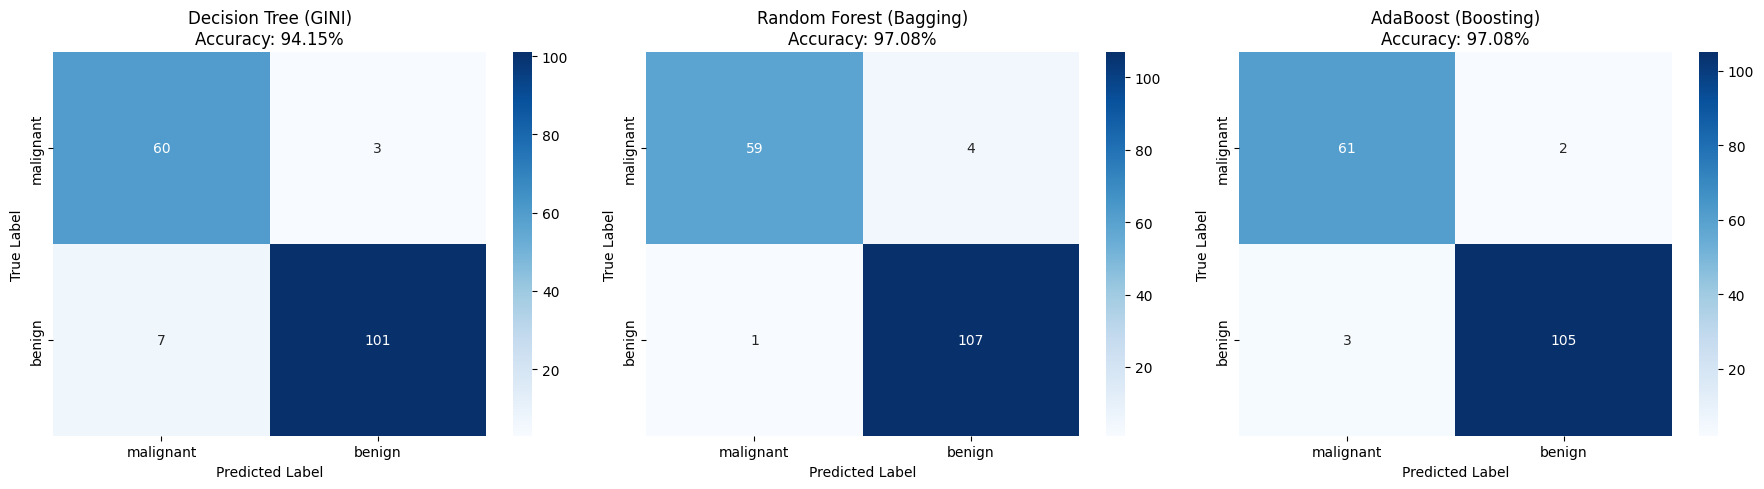

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
dt_model = DecisionTreeClassifier(criterion="gini", random_state=42)
dt_model.fit(X_train, y_train)
dt_preds = dt_model.predict(X_test)
rf_model = RandomForestClassifier(
    n_estimators=100, criterion="gini", random_state=42
)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

boost_model = AdaBoostClassifier(n_estimators=50, random_state=42)
boost_model.fit(X_train, y_train)
boost_preds = boost_model.predict(X_test)

models = {
    "Decision Tree (GINI)": dt_preds,
    "Random Forest (Bagging)": rf_preds,
    "AdaBoost (Boosting)": boost_preds,
}

print("=== Accuracy Comparison ===")
for name, preds in models.items():
    acc = accuracy_score(y_test, preds)
    print(f"{name} Accuracy: {acc * 100:.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, preds) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=data.target_names,
        yticklabels=data.target_names,
    )
    acc = accuracy_score(y_test, preds)
    ax.set_title(f"{name}\nAccuracy: {acc * 100:.2f}%")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()